In [55]:
# 회귀분석

# 그래프관련 import
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False
# 프로그램 관련 import
import pandas as pd
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error # 평균절대오차 오차범위
from sklearn.neighbors import KNeighborsClassifier # 분류 관련
from sklearn.preprocessing import StandardScaler # 정규화클래스
import numpy as np

In [56]:
# 자료는 길이, 무게 -> 길이에 따른 무게로 예상 -> 데이터 전처리 필요없음
perch_length = np.array(
    [8.4, 13.7, 15.0, 16.2, 17.4, 18.0, 18.7, 19.0, 19.6, 20.0,
    21.0, 21.0, 21.0, 21.3, 22.0, 22.0, 22.0, 22.0, 22.0, 22.5,
    22.5, 22.7, 23.0, 23.5, 24.0, 24.0, 24.6, 25.0, 25.6, 26.5,
    27.3, 27.5, 27.5, 27.5, 28.0, 28.7, 30.0, 32.8, 34.5, 35.0,
    36.5, 36.0, 37.0, 37.0, 39.0, 39.0, 39.0, 40.0, 40.0, 40.0,
    40.0, 42.0, 43.0, 43.0, 43.5, 44.0]
    )
perch_weight = np.array(
    [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
    110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
    130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
    197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
    514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
    820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
    1000.0, 1000.0]
    )

In [ ]:
# 데이터 전처리 완료
# 학습데이터, 테스트데이터 분리
train_data, test_data, train_label, test_label = train_test_split(perch_length,perch_weight)
# 데이터학습
# 데이터예측
# 정확도, 오차
# 조사 자료 범위내는 잘 맞으나, 조사가 되지 않고, 범위를 벗어나는 경우는 예측이 안 맞음

In [58]:
train_data

array([24.6, 19. , 30. , 19.6, 22.5, 23.5, 25.6, 36.5, 27.3, 37. , 26.5,
       40. , 25. , 16.2, 36. , 40. , 37. , 28. , 15. , 17.4, 32.8, 18.7,
       21. , 22.7, 43. , 22. , 40. , 22. , 21.3,  8.4, 24. , 39. , 40. ,
       21. , 35. , 22. , 22.5, 42. , 27.5, 20. , 22. , 43. ])

In [59]:
train_data = train_data.reshape(-1,1)
test_data = test_data.reshape(-1,1)
test_data[:3] # 자료 형태 확인

array([[43.5],
       [34.5],
       [13.7]])

In [60]:
# 데이터 학습
knr = KNeighborsRegressor()
knr.fit(train_data, train_label)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"effective_metric_ effective_metric_: str or callableThe distance metric to use. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'
"effective_metric_params_ effective_metric_params_: dictAdditional keyword arguments for the metric function. For most metricswill be same with `metric_params` parameter, but may also contain the`p` parameter value if the `effective_metric_` attribute is set to'minkowski'.",dict,{}


In [61]:
# 데이터 예측
predict = knr.predict(test_data)
print("예측치:", predict)

예측치: [974.   685.8   49.08 269.6  145.   165.6   72.9  245.   897.   974.
 245.   897.   123.   131.  ]


In [62]:
# 정확도, 오차
score = knr.score(train_data,train_label)
score2 = knr.score(test_data,test_label)
print("정확도:", score)
print("정확도:", score2)

정확도: 0.9821082534303125
정확도: 0.9396674618773125


In [63]:
# 오차범위
mae = mean_absolute_error(test_label,predict)
print("오차범위",mae)

오차범위 49.91285714285714


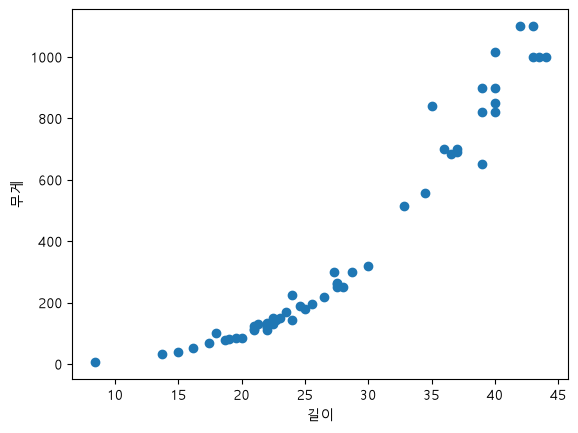

In [64]:
# 산점도 그래프
plt.scatter(perch_length,perch_weight)
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()

In [68]:
# 길이를 입력받아 무게를 예측하시오.
# 길이를 입력하세요(예: 27)
# 예측무게 : ?

In [69]:
length = input("길이를 입력하세요:")
length = float(length)
forca = knr.predict([[length]])
print("예측무게:", forca)

예측무게: [611.8]


In [72]:
distances, indexes = knr.kneighbors([[33]])
indexes

array([[20, 34, 14,  2,  7]])

NameError: name 'i_data' is not defined

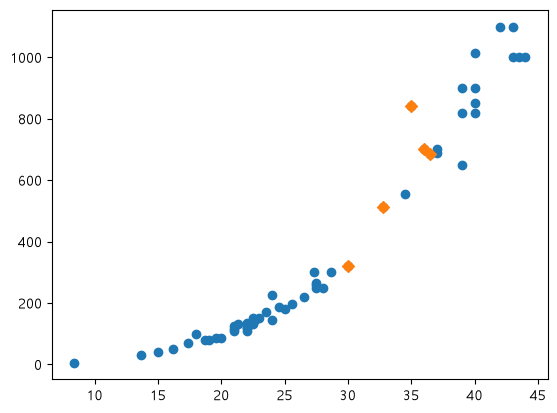

In [ ]:
# 산점도 그래프
plt.scatter(perch_length,perch_weight)
plt.scatter(train_data[indexes], train_label[indexes], marker='o')  # maker -> marker 수정
plt.scatter(33,685.5,marker='*')